# East Africa Cropland NDVI by County 2026

Monthly NDVI over cropland for 243 units in Kenya, Tanzania, Uganda, Rwanda. A free sample from [NuaSense](https://agriculture-data.com), East African agricultural data; also on [Hugging Face](https://huggingface.co/datasets/nuasense/east-africa-cropland-ndvi) (CC BY-NC 4.0).

In [1]:
import glob, os
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#ecebe7", "axes.axisbelow": True, "font.size": 10})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"

def load(name, hf_url):
    # On Kaggle the CSV sits under /kaggle/input; in Colab or on your machine the same table
    # is read straight from Hugging Face.
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True) + glob.glob(f"**/{name}", recursive=True)
    return pd.read_csv(hits[0]) if hits else pd.read_parquet(hf_url)

df = load("east_africa_cropland_ndvi_monthly_2026.csv", "https://huggingface.co/datasets/nuasense/east-africa-cropland-ndvi/resolve/main/data/east_africa_cropland_ndvi_monthly_2026.parquet")
print(f"{len(df):,} rows")
df.head()

1,840 rows


,country,country_name,unit_type,unit_name,unit_id,month,ndvi,composites
0,KE,Kenya,county,Baringo,baringo,2026-01,0.4543,2
1,KE,Kenya,county,Baringo,baringo,2026-02,0.3769,6
2,KE,Kenya,county,Baringo,baringo,2026-03,0.4731,7
3,KE,Kenya,county,Baringo,baringo,2026-04,0.5506,6
4,KE,Kenya,county,Baringo,baringo,2026-05,0.6510,4


## The season by country

Median cropland NDVI across each country's units, month by month.

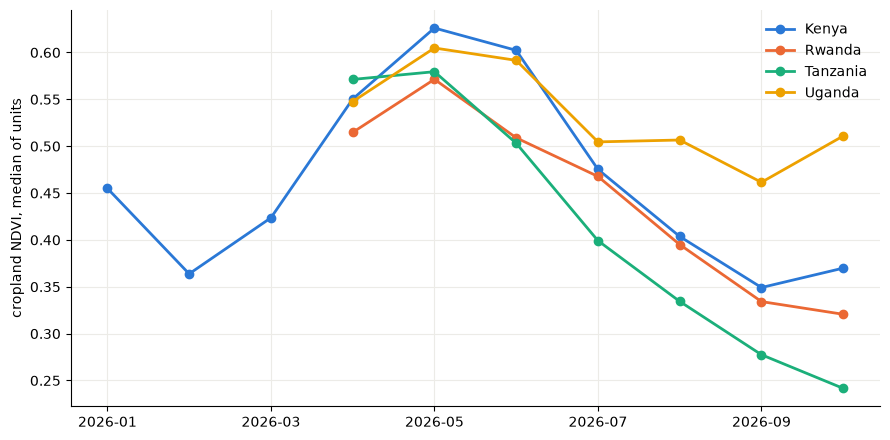

In [2]:
m = df.pivot_table(index="month", columns="country_name", values="ndvi", aggfunc="median")
ax = m.plot(color=[BLUE, ORANGE, AQUA, "#eda100"], linewidth=2, marker="o")
ax.set_ylabel("cropland NDVI, median of units"); ax.set_xlabel("")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## Greenest and least green Kenyan counties, latest month

In [3]:
ke = df[df.country == "KE"]
last = ke[ke.month == ke.month.max()].sort_values("ndvi")
pd.concat([last.head(5), last.tail(5)])[["unit_name", "month", "ndvi", "composites"]]

,unit_name,month,ndvi,composites
248,Marsabit,2026-10,0.1874,4
99,Kajiado,2026-10,0.1949,4
428,Turkana,2026-10,0.2052,4
89,Isiolo,2026-10,0.2150,4
458,Wajir,2026-10,0.2258,4
159,Kisii,2026-10,0.5669,4
29,Bungoma,2026-10,0.5762,4
109,Kakamega,2026-10,0.5774,4
448,Vihiga,2026-10,0.6015,4
318,Nandi,2026-10,0.6133,4


## Change since the start of the year

Kenyan counties whose cropland greened most and least between January and the latest month.

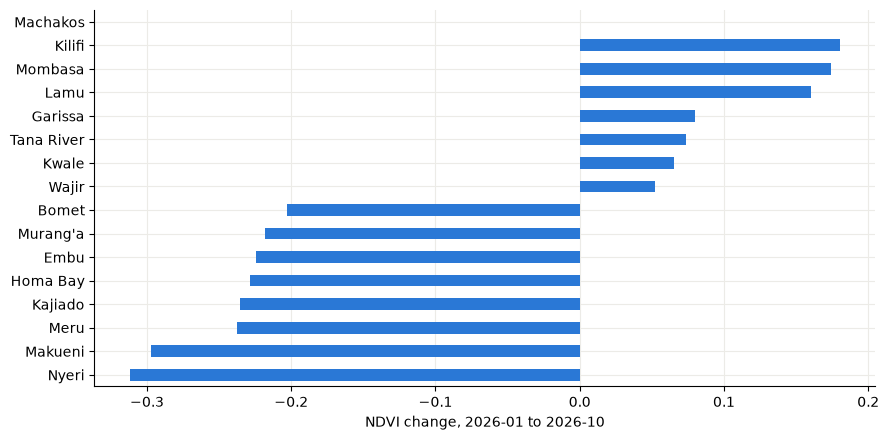

In [4]:
w = ke.pivot_table(index="unit_name", columns="month", values="ndvi")
change = (w[w.columns[-1]] - w[w.columns[0]]).sort_values()
ax = pd.concat([change.head(8), change.tail(8)]).plot.barh(color=BLUE)
ax.set_xlabel(f"NDVI change, {w.columns[0]} to {w.columns[-1]}"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

## The full data

This sample holds monthly means. The NuaSense API serves every composite, NDRE, SAVI and NDMI next to NDVI, a 300 m series back to 2018, and each unit's seasonal normal.

```
pip install nuasense
```

A key with a free monthly allowance comes from [platform.nuasense.com](https://platform.nuasense.com/start). On Kaggle, store it as a secret named `NUASENSE_API_KEY` (Add-ons → Secrets). Fields and filters: [agriculture-data.com](https://agriculture-data.com/datasets/demand-and-crop-stress/demand-indices/).

In [5]:
# Runs only when a NuaSense key is available (Kaggle secret NUASENSE_API_KEY or an environment variable).
try:
    from kaggle_secrets import UserSecretsClient
    os.environ.setdefault("NUASENSE_API_KEY", UserSecretsClient().get_secret("NUASENSE_API_KEY"))
except Exception:
    pass

if os.environ.get("NUASENSE_API_KEY"):
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nuasense"], check=False)
    import nuasense
    ns = nuasense.Client()
    rows = ns.rows("/market/demand-indices", start="-60d", limit=100, county="nakuru", index="ndvi")
    display(pd.DataFrame(rows).head())
else:
    print("No NUASENSE_API_KEY set: add it as a Kaggle secret (Add-ons -> Secrets) to read the full series.")

No NUASENSE_API_KEY set: add it as a Kaggle secret (Add-ons -> Secrets) to read the full series.
